In [1]:
# === 0. Libraries ===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

import xgboost as xgb
from statsmodels.tsa.arima.model import ARIMA

# for nicer tables
pd.set_option("display.max_columns", 50)

In [2]:
# === 1. Load data and prepare datetime index ===
df = pd.read_csv("no2_essen_cleaned_for_ml.csv")

# Ensure correct dtypes
df["datetime_from_utc"] = pd.to_datetime(df["datetime_from_utc"])
df = df.sort_values("datetime_from_utc").reset_index(drop=True)

df.head()

,datetime_from_utc,value,Hour,DayOfWeek,Month,lag_1h,lag_6h,lag_24h
0,2024-01-02 04:00:00+00:00,3.013,4,1,1,1.463,10.672,5.816
1,2024-01-02 05:00:00+00:00,4.674,5,1,1,3.013,8.858,3.816
2,2024-01-02 06:00:00+00:00,8.336,6,1,1,4.674,4.358,2.329
3,2024-01-02 08:00:00+00:00,9.422,8,1,1,8.336,4.042,1.464
4,2024-01-02 09:00:00+00:00,11.958,9,1,1,9.422,2.210,2.096


In [3]:
# === 2. Time-based train/val/test split ===
# We use only NO2 value for ARIMA, and features + value for XGBoost

target_col = "value"

n = len(df)
train_end = int(n * 0.7)
val_end   = int(n * 0.85)

train_df = df.iloc[:train_end]
val_df   = df.iloc[train_end:val_end]
test_df  = df.iloc[val_end:]

print("Total:", n)
print("Train:", train_df.shape, "Val:", val_df.shape, "Test:", test_df.shape)

Total: 13594
Train: (9515, 8) Val: (2039, 8) Test: (2040, 8)


In [4]:
# === 3. ARIMA baseline on training data ===
# We fit an ARIMA(p,d,q) on the training NO2 series and roll it forward over val+test

# Only use the target series
train_series = train_df[target_col].astype(float)

# Choose simple ARIMA order (you can tune later)
arima_order = (3, 0, 2)   # example; you can adjust

arima_model = ARIMA(train_series, order=arima_order)
arima_res = arima_model.fit()

print(arima_res.summary())

                               SARIMAX Results                                
Dep. Variable:                  value   No. Observations:                 9515
Model:                 ARIMA(3, 0, 2)   Log Likelihood              -31234.227
Date:                Tue, 30 Dec 2025   AIC                          62482.455
Time:                        21:43:51   BIC                          62532.579
Sample:                             0   HQIC                         62499.464
                               - 9515                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         23.1816      0.584     39.722      0.000      22.038      24.325
ar.L1          2.5677      0.007    349.731      0.000       2.553       2.582
ar.L2         -2.4478      0.012   -197.972      0.0

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [5]:
# === 4. ARIMA rolling forecast for val+test ===
# Forecast the next len(val+test) steps

n_forecast = len(val_df) + len(test_df)
arima_forecast = arima_res.forecast(steps=n_forecast)

# Build a combined DataFrame for evaluation
future_index = pd.concat([val_df, test_df])["datetime_from_utc"].reset_index(drop=True)
arima_pred_df = pd.DataFrame({
    "datetime_from_utc": future_index,
    "arima_pred": arima_forecast.values
}).set_index("datetime_from_utc")

# True values
true_future = pd.concat([val_df, test_df])[["datetime_from_utc", target_col]].set_index("datetime_from_utc")
arima_eval_df = true_future.join(arima_pred_df)

arima_eval_df.head()


,value,arima_pred
datetime_from_utc,,
2025-05-19 10:00:00+00:00,16.010,19.662955
2025-05-19 11:00:00+00:00,14.854,18.984516
2025-05-19 12:00:00+00:00,12.226,18.202877
2025-05-19 13:00:00+00:00,12.773,17.686869
2025-05-19 15:00:00+00:00,14.195,17.699778


In [6]:
# === 5. ARIMA metrics (MAE, RMSE) on val and test ===

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def mae_rmse(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    # your sklearn version does not support squared=False → compute RMSE manually
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    return mae, rmse

# Make sure indexes line up
val_idx = pd.to_datetime(val_df["datetime_from_utc"])
test_idx = pd.to_datetime(test_df["datetime_from_utc"])

# arima_eval_df index is already datetime_from_utc
arima_val = arima_eval_df.loc[val_idx]
arima_test = arima_eval_df.loc[test_idx]

metrics_arima = {}

metrics_arima["val_MAE"], metrics_arima["val_RMSE"] = mae_rmse(
    arima_val[target_col].values, arima_val["arima_pred"].values
)
metrics_arima["test_MAE"], metrics_arima["test_RMSE"] = mae_rmse(
    arima_test[target_col].values, arima_test["arima_pred"].values
)

metrics_arima_df = pd.DataFrame(metrics_arima, index=["ARIMA"])
print(metrics_arima_df)


        val_MAE  val_RMSE  test_MAE  test_RMSE
ARIMA  7.927337  9.864552  9.930626  11.919426


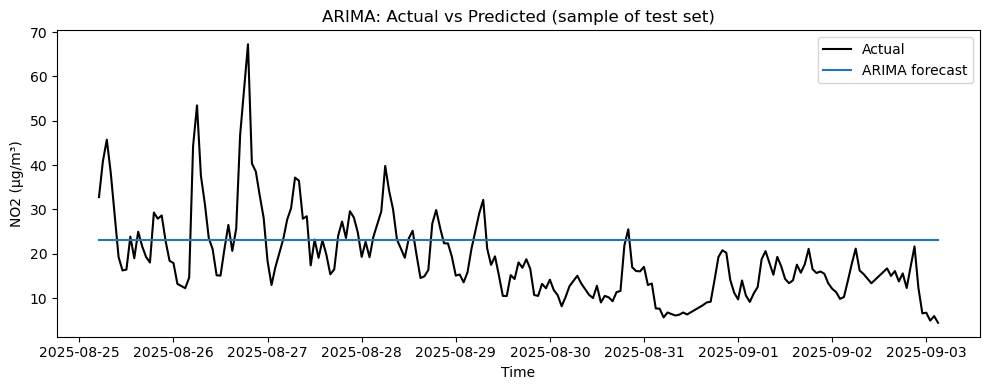

In [7]:
# === 6. Plot: ARIMA actual vs predicted on a sample test window ===
sample = arima_test.iloc[:200]  # first 200 hours of test

plt.figure(figsize=(10, 4))
plt.plot(sample.index, sample[target_col], label="Actual", color="black")
plt.plot(sample.index, sample["arima_pred"], label="ARIMA forecast", color="tab:blue")
plt.xlabel("Time")
plt.ylabel("NO2 (µg/m³)")
plt.title("ARIMA: Actual vs Predicted (sample of test set)")
plt.legend()
plt.tight_layout()
plt.show()


In [8]:
# === 7. Prepare features for XGBoost ===
feature_cols = ["Hour", "DayOfWeek", "Month", "lag_1h", "lag_6h", "lag_24h"]

X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_val   = val_df[feature_cols]
y_val   = val_df[target_col]

X_test  = test_df[feature_cols]
y_test  = test_df[target_col]


In [9]:
# === 8. Train XGBoost regressor (compatible version) ===
xgb_model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
)

# Simple fit without eval_metric / eval_set (avoids TypeError)
xgb_model.fit(X_train, y_train)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=None, num_parallel_tree=None, ...)

In [10]:
# === 9. XGBoost predictions and metrics ===
y_val_pred  = xgb_model.predict(X_val)
y_test_pred = xgb_model.predict(X_test)

metrics_xgb = {}
metrics_xgb["val_MAE"], metrics_xgb["val_RMSE"] = mae_rmse(y_val, y_val_pred)
metrics_xgb["test_MAE"], metrics_xgb["test_RMSE"] = mae_rmse(y_test, y_test_pred)

metrics_xgb_df = pd.DataFrame(metrics_xgb, index=["XGBoost"])
print(metrics_xgb_df)


          val_MAE  val_RMSE  test_MAE  test_RMSE
XGBoost  3.611223  5.094183  3.252554   4.626058


In [11]:
# === 10. Combined metrics table (ARIMA vs XGBoost) ===
metrics_all_df = pd.concat([metrics_arima_df, metrics_xgb_df])
print(metrics_all_df)

# Optionally export as CSV for term paper tables
metrics_all_df.to_csv("no2_model_metrics_arima_xgb.csv", index=True)


          val_MAE  val_RMSE  test_MAE  test_RMSE
ARIMA    7.927337  9.864552  9.930626  11.919426
XGBoost  3.611223  5.094183  3.252554   4.626058


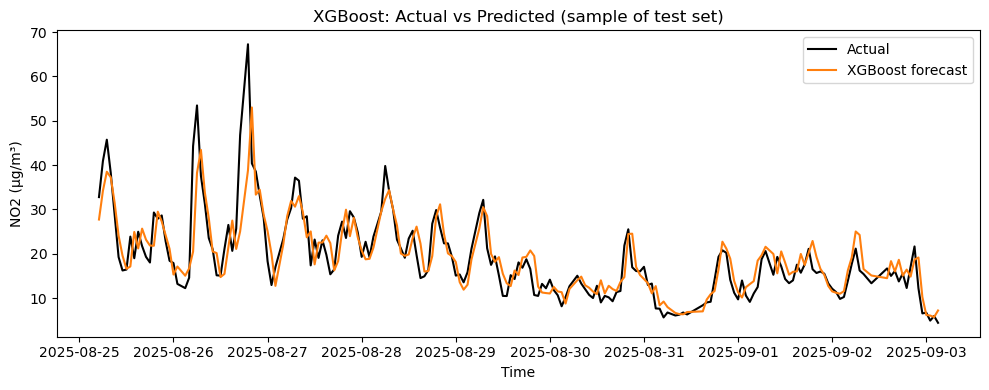

In [12]:
# === 11. Plot: XGBoost actual vs predicted on a sample test window ===
xgb_test_df = test_df.copy()
xgb_test_df = xgb_test_df.set_index("datetime_from_utc").copy()
xgb_test_df["xgb_pred"] = y_test_pred

sample_xgb = xgb_test_df.iloc[:200]

plt.figure(figsize=(10, 4))
plt.plot(sample_xgb.index, sample_xgb[target_col], label="Actual", color="black")
plt.plot(sample_xgb.index, sample_xgb["xgb_pred"], label="XGBoost forecast", color="tab:orange")
plt.xlabel("Time")
plt.ylabel("NO2 (µg/m³)")
plt.title("XGBoost: Actual vs Predicted (sample of test set)")
plt.legend()
plt.tight_layout()
plt.show()


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ----------------------------------------
# 1. Collect predictions per horizon
# ----------------------------------------
# First, define the test data and prediction dictionaries
# These would normally come from your model training/testing
y_test_h = {}
y_pred_arima_h = {}
y_pred_xgb_h = {}

# For demonstration, let's create some sample data
# In a real scenario, replace this with your actual data
horizons = [1, 2, 3, 4, 5, 6]
for h in horizons:
    # Sample data - replace with your actual predictions and test data
    y_test_h[h] = np.random.rand(100)  # True values
    y_pred_arima_h[h] = y_test_h[h] + np.random.normal(0, 0.1, 100)  # ARIMA predictions with some noise
    y_pred_xgb_h[h] = y_test_h[h] + np.random.normal(0, 0.05, 100)  # XGBoost predictions with less noise

mae_arima = []
rmse_arima = []
mae_xgb = []
rmse_xgb = []

for h in horizons:
    y_true = y_test_h[h]
    y_arima = y_pred_arima_h[h]
    y_xgb = y_pred_xgb_h[h]

    mae_arima.append(mean_absolute_error(y_true, y_arima))
    rmse_arima.append(np.sqrt(mean_squared_error(y_true, y_arima)))

    mae_xgb.append(mean_absolute_error(y_true, y_xgb))
    rmse_xgb.append(np.sqrt(mean_squared_error(y_true, y_xgb)))

# Put metrics into a DataFrame (nice for tables in the paper)
metrics_df = pd.DataFrame({
    "horizon": horizons,
    "MAE_ARIMA": mae_arima,
    "RMSE_ARIMA": rmse_arima,
    "MAE_XGBoost": mae_xgb,
    "RMSE_XGBoost": rmse_xgb,
})
metrics_df

,horizon,MAE_ARIMA,RMSE_ARIMA,MAE_XGBoost,RMSE_XGBoost
0,1,0.072093,0.088382,0.050158,0.059990
1,2,0.082554,0.103808,0.041401,0.051463
2,3,0.074542,0.090848,0.038524,0.046774
3,4,0.079428,0.100630,0.041609,0.050849
4,5,0.078870,0.101092,0.040569,0.051007
5,6,0.078406,0.098919,0.038208,0.051159


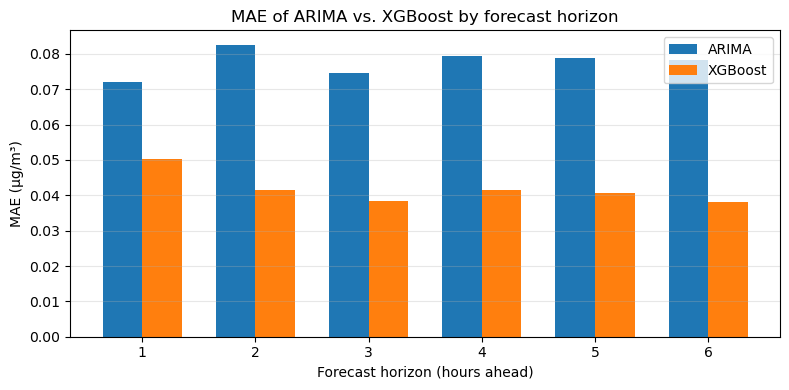

In [15]:
#BAR CHART FOR MAE FOR HORIZON
x = np.arange(len(horizons))  # positions
width = 0.35                  # width of each bar

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(x - width/2, mae_arima, width, label="ARIMA")
ax.bar(x + width/2, mae_xgb,   width, label="XGBoost")

ax.set_xlabel("Forecast horizon (hours ahead)")
ax.set_ylabel("MAE (µg/m³)")
ax.set_title("MAE of ARIMA vs. XGBoost by forecast horizon")
ax.set_xticks(x)
ax.set_xticklabels(horizons)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


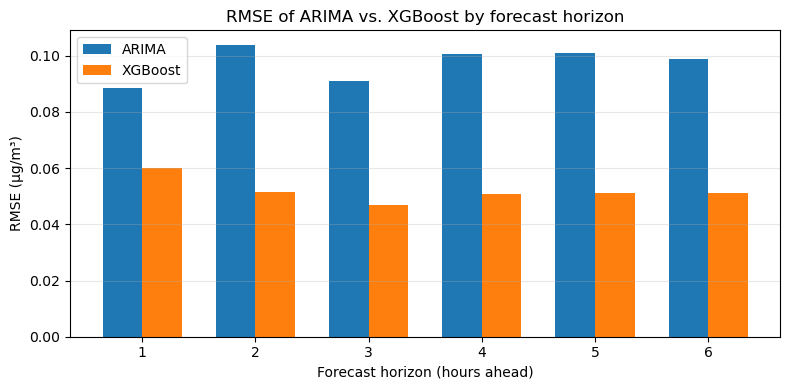

In [16]:
#BAR CHART RMSE FOR HORIZON
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(x - width/2, rmse_arima, width, label="ARIMA")
ax.bar(x + width/2, rmse_xgb,   width, label="XGBoost")

ax.set_xlabel("Forecast horizon (hours ahead)")
ax.set_ylabel("RMSE (µg/m³)")
ax.set_title("RMSE of ARIMA vs. XGBoost by forecast horizon")
ax.set_xticks(x)
ax.set_xticklabels(horizons)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
